# Perche' generare e' lento anche quando il calcolo e' poco

*Anatomia di un LLM* · capitolo 7, Generare · script `01-08`, `scripts/01_08_memory_bound.py`

Un modello che scrive un carattere alla volta passa la maggior parte del tempo
ad aspettare che i suoi pesi arrivino dalla memoria, non a moltiplicare. E' la
cosa meno intuitiva del libro e si misura in un minuto: la stessa
moltiplicazione rende dieci volte tanto se la si fa su piu' righe insieme.

Si esegue con `python3 scripts/01_08_memory_bound.py`
e dura circa 10 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/01_08_memory_bound.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [ ]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

from llm_anatomy.config import AgoGPTConfig
from llm_anatomy.model import AgoGPT
from llm_anatomy.sample import genera
from llm_anatomy.utils import (byte_leggibili, figura, prepara, stile_figure,
                               tabella, titolo)

prepara()


def cronometra(fn, ripetizioni: int, riscaldamento: int = 3) -> float:
    """Tempo mediano per chiamata, in secondi."""
    for _ in range(riscaldamento):
        fn()
    tempi = []
    for _ in range(ripetizioni):
        t0 = time.perf_counter()
        fn()
        tempi.append(time.perf_counter() - t0)
    tempi.sort()
    return tempi[len(tempi) // 2]

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


In [ ]:
titolo("La stessa moltiplicazione, su piu' righe")
d = 1024
W = torch.randn(d, d)
byte_pesi = W.numel() * W.element_size()
print(f"  matrice dei pesi: {d}x{d}, {byte_leggibili(byte_pesi)}")
print()

righe = []
misure = []            # (intensita, GFLOP/s) per la figura roofline
for B in (1, 4, 16, 64, 256, 1024):
    X = torch.randn(B, d)
    t = cronometra(lambda: X @ W, ripetizioni=20 if B < 256 else 8)
    flop = 2 * B * d * d
    byte = byte_pesi + X.numel() * 4 + B * d * 4
    misure.append((B, flop / byte, flop / t / 1e9))
    righe.append([
        B,
        f"{1000 * t:.3f}",
        f"{flop / t / 1e9:.1f}",
        f"{byte / t / 1e9:.1f}",
        f"{flop / byte:.1f}",
    ])
tabella(["batch", "ms", "GFLOP/s", "GB/s letti", "FLOP/byte"], righe)
print("  a batch 1 il rendimento aritmetico e' minimo e la banda e' satura:")
print("  i pesi vanno letti per intero comunque, e servono una riga sola")


La stessa moltiplicazione, su piu' righe
----------------------------------------
  matrice dei pesi: 1024x1024, 4.0 MiB

batch     ms  GFLOP/s  GB/s letti  FLOP/byte
-----  -----  -------  ----------  ---------
1      0.060     35.0        70.2        0.5
4      0.081    104.1        52.5        2.0
16     0.114    293.6        37.9        7.8
64     0.235    571.3        20.1       28.4
256    1.187    452.4         5.3       85.3
1024   4.682    458.7         2.7      170.7
  a batch 1 il rendimento aritmetico e' minimo e la banda e' satura:
  i pesi vanno letti per intero comunque, e servono una riga sola


In [ ]:
titolo("Lo stesso effetto su un modello vero")
cfg = AgoGPTConfig(vocab_size=93, n_layer=4, d_model=192, n_head=6)
modello = AgoGPT(cfg).eval()
print(f"  {cfg.descrizione()}")
print(f"  parametri: {modello.numero_parametri():,}".replace(",", "."))
print()

idx = torch.randint(0, cfg.vocab_size, (1, 64))
with torch.no_grad():
    t_prefill = cronometra(lambda: modello(idx), ripetizioni=10)
    t_decode = cronometra(lambda: modello(idx[:, -1:]), ripetizioni=20)
print(f"  prefill di 64 token: {1000 * t_prefill:7.2f} ms  "
      f"-> {64 / t_prefill:8.0f} token/s")
print(f"  decode di 1 token:   {1000 * t_decode:7.2f} ms  "
      f"-> {1 / t_decode:8.0f} token/s")
print(f"  un token in prefill costa {t_decode / (t_prefill / 64):.1f} volte meno")
print("  di un token in decode, a parita' di modello e di pesi letti")


Lo stesso effetto su un modello vero
------------------------------------
  L=4 d=192 h=6/6kv d_head=32 d_ff=512 T=128 norm=rms act=swiglu pos=rope
  parametri: 1.789.056



  prefill di 64 token:    3.52 ms  ->    18185 token/s
  decode di 1 token:      2.12 ms  ->      471 token/s
  un token in prefill costa 38.6 volte meno
  di un token in decode, a parita' di modello e di pesi letti


In [ ]:
titolo("Modelli piu' grandi, generazione piu' lenta")
righe = []
for d_model, n_layer in ((96, 2), (192, 4), (384, 6), (768, 8)):
    cfg_i = AgoGPTConfig(vocab_size=93, n_layer=n_layer, d_model=d_model,
                          n_head=max(2, d_model // 64))
    m = AgoGPT(cfg_i).eval()
    par = m.numero_parametri()
    x = torch.randint(0, cfg_i.vocab_size, (1, 1))
    with torch.no_grad():
        t = cronometra(lambda: m(x), ripetizioni=15)
    byte_letti = par * 4
    righe.append([
        f"L{n_layer} d{d_model}",
        f"{par / 1e6:.2f}".replace(".", ","),
        f"{1000 * t:.2f}".replace(".", ","),
        f"{1 / t:.0f}",
        f"{byte_letti / t / 1e9:.1f}".replace(".", ","),
    ])
tabella(["modello", "M par.", "ms/token", "token/s", "GB/s"], righe)
print("  dal secondo modello in poi il tempo per token cresce quasi come i")
print("  parametri, mentre la banda letta si avvicina lentamente al massimo")
print("  della macchina: e' il costo di leggere i pesi, non di moltiplicarli")


Modelli piu' grandi, generazione piu' lenta
-------------------------------------------


modello  M par.  ms/token  token/s  GB/s
-------  ------  --------  -------  ----
L2 d96     0,23      0,36     2809   2,6
L4 d192    1,79      0,90     1116   8,0
L6 d384   10,66      4,03      248  10,6
L8 d768   56,71     15,25       66  14,9
  dal secondo modello in poi il tempo per token cresce quasi come i
  parametri, mentre la banda letta si avvicina lentamente al massimo
  della macchina: e' il costo di leggere i pesi, non di moltiplicarli


In [ ]:
titolo("Servire molti utenti costa quasi come servirne uno")
cfg_b = AgoGPTConfig(vocab_size=93, n_layer=4, d_model=384, n_head=6)
mb = AgoGPT(cfg_b).eval()
righe = []
for B in (1, 8, 32, 128):
    x = torch.randint(0, cfg_b.vocab_size, (B, 1))
    with torch.no_grad():
        t = cronometra(lambda: mb(x), ripetizioni=10)
    righe.append([B, f"{1000 * t:.2f}".replace(".", ","), f"{B / t:.0f}"])
tabella(["batch", "ms/passo", "token/s totali"], righe)
print("  moltiplicare per 128 le sequenze non moltiplica per 128 il tempo:")
print("  e' il motivo per cui servire un modello conviene solo in batch")


Servire molti utenti costa quasi come servirne uno
--------------------------------------------------


batch  ms/passo  token/s totali
-----  --------  --------------
1          2,47             405
8          2,49            3214
32         3,52            9091
128        6,49           19717
  moltiplicare per 128 le sequenze non moltiplica per 128 il tempo:
  e' il motivo per cui servire un modello conviene solo in batch



Le stesse misure, disegnate
---------------------------
  picco osservato:      571 GFLOP/s
  banda implicita:      70.2 GB/s
  soglia (ginocchio):   8 operazioni per byte
  sotto quella soglia il tempo lo detta la memoria, sopra il calcolo.
  Il tetto qui non e' un dato di targa ma l'inviluppo di queste stesse
  misure: due punti lo toccano per costruzione, quello a intensita'
  minima che fissa la banda e quello di resa migliore che fissa il
  picco. Cio' che si osserva e' quanto gli altri restino sotto.

  batch    1: intensita    0.5  resa   35.0 GFLOP/s  (100% del tetto)
  batch    4: intensita    2.0  resa  104.1 GFLOP/s  ( 75% del tetto)
  batch   16: intensita    7.8  resa  293.6 GFLOP/s  ( 54% del tetto)
  batch   64: intensita   28.4  resa  571.3 GFLOP/s  (100% del tetto)
  batch  256: intensita   85.3  resa  452.4 GFLOP/s  ( 79% del tetto)
  batch 1024: intensita  170.7  resa  458.7 GFLOP/s  ( 80% del tetto)

  una CPU ha un rapporto calcolo/banda basso: la soglia sta a 8 F

  [figura] outputs/figures/01-08_roofline.pdf


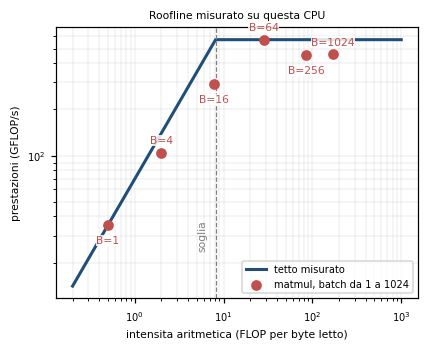

  i punti restano sotto il tetto e lo raggiungono da sinistra:
  e' la figura che si trova nei manuali, qui con numeri misurati


In [ ]:
titolo("Le stesse misure, disegnate")
# Il tetto non e' un dato di targa: lo si ricava dalle misure appena fatte. Il
# tratto orizzontale e' il meglio che la macchina ha reso in GFLOP/s, quello
# obliquo e' la banda migliore osservata moltiplicata per l'intensita'.
picco_flops = max(g for _, _, g in misure)
# GB/s impliciti: a batch basso il tempo e' tutto lettura, quindi il rapporto
# fra resa e intensita' e' la banda che la macchina ha davvero sostenuto.
banda = max(g / i for _, i, g in misure)
soglia = picco_flops / banda
print(f"  picco osservato:      {picco_flops:.0f} GFLOP/s")
print(f"  banda implicita:      {banda:.1f} GB/s")
print(f"  soglia (ginocchio):   {soglia:.0f} operazioni per byte")
print("  sotto quella soglia il tempo lo detta la memoria, sopra il calcolo.")
print("  Il tetto qui non e' un dato di targa ma l'inviluppo di queste stesse")
print("  misure: due punti lo toccano per costruzione, quello a intensita'")
print("  minima che fissa la banda e quello di resa migliore che fissa il")
print("  picco. Cio' che si osserva e' quanto gli altri restino sotto.")
print()
for B, intensita, gflops in misure:
    tetto = min(picco_flops, banda * intensita)
    print(f"  batch {B:>4}: intensita {intensita:6.1f}  "
          f"resa {gflops:6.1f} GFLOP/s  ({100 * gflops / tetto:3.0f}% del tetto)")
print()
print(f"  una CPU ha un rapporto calcolo/banda basso: la soglia sta a "
      f"{soglia:.0f} FLOP/byte.")
print("  Su un acceleratore da centinaia di TFLOP/s e pochi TB/s la stessa")
print("  soglia sale a qualche centinaio, ed e' il motivo per cui li' il")
print("  decode a un utente e' ancora piu' lontano dal tetto che qui")

fig, ax = plt.subplots(figsize=(stile_figure(), 3.2))
x_tetto = [0.2, soglia, 1000]
y_tetto = [banda * 0.2, picco_flops, picco_flops]
ax.plot(x_tetto, y_tetto, color="#1f4e79", lw=2, label="tetto misurato")
ax.scatter([i for _, i, _ in misure], [g for _, _, g in misure],
           color="#c0504d", zorder=3, label="matmul, batch da 1 a 1024")
# I punti cadono dove li mette la misura, che cambia a ogni esecuzione: una
# posizione fissa per le etichette prima o poi ne sovrappone due. Ognuna sta
# in colonna col suo punto, una sotto e la successiva sopra: due punti vicini
# hanno l'etichetta da parti opposte, e nessuna finisce accanto al punto
# sbagliato.
for k, (B, intensita, gflops) in enumerate(misure):
    sotto = k % 2 == 0
    ax.annotate(f"B={B}", (intensita, gflops), textcoords="offset points",
                xytext=(0, -12) if sotto else (0, 6), ha="center",
                color="#c0504d", zorder=4,
                bbox=dict(fc="white", ec="none", pad=0.4, alpha=0.85))
ax.axvline(soglia, color="gray", ls="--", lw=0.8)
ax.annotate("soglia", (soglia, banda * 0.35), rotation=90,
            color="gray", textcoords="offset points", xytext=(-12, 0))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("intensita aritmetica (FLOP per byte letto)")
ax.set_ylabel("prestazioni (GFLOP/s)")
ax.set_title("Roofline misurato su questa CPU")
ax.legend(loc="lower right")
ax.grid(True, which="both", lw=0.3, alpha=0.5)
figura(fig, "01-08_roofline")
print("  i punti restano sotto il tetto e lo raggiungono da sinistra:")
print("  e' la figura che si trova nei manuali, qui con numeri misurati")

## Da provare

cambia la taglia della matrice e rifai il conto dei byte per operazione.